# Part 3 lab: a GLM for a count outcome — emergency department visits

**Maths for Data Science III · MSHA · Generalized linear models, Part 3 · SOLUTIONS**

The outcome is now a **count**: how many times each patient returned to the emergency department (ED) after discharge. The **linear predictor** stays the same as in Parts 1 and 2; the other two components change to a **Poisson distribution** and a **log link**. To keep things simple, we use only the patients followed for the full 6 months, so every count covers the same period.

In this notebook you will:

1. Look at a count outcome and see why linear regression is a poor fit.
2. Fit Poisson regression and read incidence rate ratios.
3. Check for overdispersion and switch to a negative binomial model.
4. Predict expected visits for two patients.

**Data:** read directly from the course GitHub repository (see *The dataset* below).

## The dataset: a heart-failure discharge cohort

All three GLM sessions use the same dataset: **2,000 adults discharged alive after an admission for heart failure** from **25 US hospitals**, one row per patient. The data are **simulated for teaching**: no row describes a real patient or hospital, and they were generated with known effects so we can check how close each model gets to the truth.

**Source:** [`hf_cohort.csv`](https://raw.githubusercontent.com/thousandoaks/Maths4DS-III/refs/heads/main/datasets/hf_cohort.csv) in the course GitHub repository. The file is complete: no missing values.

| Variable | Description | Units / values |
|---|---|---|
| `age` | Age at admission | years |
| `egfr` | Estimated glomerular filtration rate (kidney function) | mL/min/1.73 m² |
| `diabetes` | Diabetes on the problem list | 1 = yes, 0 = no |
| `prior_admits_12m` | Hospital admissions in the previous 12 months | count |
| `ed_visits_6m` | **Outcome:** ED visits during follow-up | count |
| `followup_days` | Days of follow-up for ED visits (we keep patients with the full 182 days) | 30 to 182 days |

The file also contains `patient_id`, `hospital_id`, `female` and the outcomes used in Parts 1 and 2 (`sbp_followup`, `readmit_30d`) and in the Part 1 lecture (`los_days`).

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats

fam = sm.families

In [2]:
DATA_URL = "https://raw.githubusercontent.com/thousandoaks/Maths4DS-III/refs/heads/main/datasets/hf_cohort.csv"
df = pd.read_csv(DATA_URL)
print(df.shape)
df.head()

(2000, 12)


,patient_id,hospital_id,age,female,egfr,diabetes,prior_admits_12m,los_days,sbp_followup,readmit_30d,ed_visits_6m,followup_days
0,HF026-00001,H02,75,0,52,0,2,7.4,147,0,1,182
1,HF026-00002,H01,84,1,48,0,0,1.6,130,0,0,182
2,HF026-00003,H24,81,0,72,0,1,1.1,143,0,0,182
3,HF026-00004,H24,62,0,50,1,1,1.9,140,0,1,122
4,HF026-00005,H12,69,0,39,0,1,0.6,145,0,1,182


We keep only the patients followed for the full 6 months (182 days), so every count covers the same period. (With unequal follow-up, the alternative is to keep everyone and add log(follow-up time) to the model as an offset.)

As before, age and eGFR are centred and scaled **per 10 units**, so the intercept describes a **reference patient**: 75 years old, eGFR 60, no diabetes, no prior admissions.

In [3]:
df = df[df["followup_days"] == 182].copy()
print(f"Patients followed for the full 6 months: {len(df)}")

df["age10"] = (df["age"] - 75) / 10
df["egfr10"] = (df["egfr"] - 60) / 10

RHS = "~ age10 + egfr10 + diabetes + prior_admits_12m"

Patients followed for the full 6 months: 1645


## 1. Look at the outcome first

Mean 1.08   variance 1.86   no visits: 43%   maximum: 14


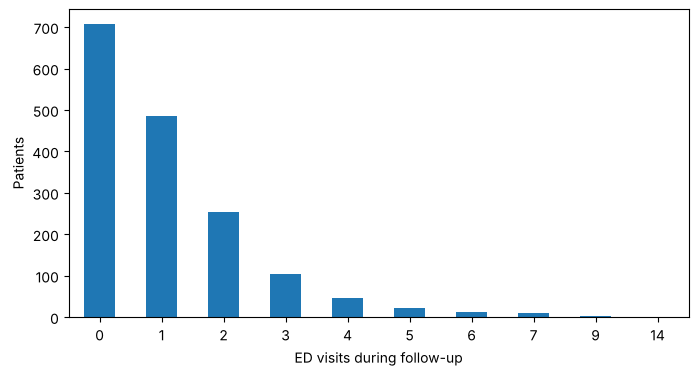

In [4]:
y = df["ed_visits_6m"]
print(f"Mean {y.mean():.2f}   variance {y.var():.2f}   no visits: {(y == 0).mean():.0%}   maximum: {y.max()}")

y.value_counts().sort_index().plot.bar(figsize=(8, 4), xlabel="ED visits during follow-up", ylabel="Patients", rot=0)
plt.show()

**Question 1.** What kind of number is `ed_visits_6m`, and what do you notice?

*Answer.* It is a **count**: whole numbers, never negative, piled up at 0 and 1 (43% of patients had no visit) with a long tail of frequent attenders. The mean (1.08) is smaller than the variance (1.86), a first hint of extra variation.

## 2. Why not linear regression?

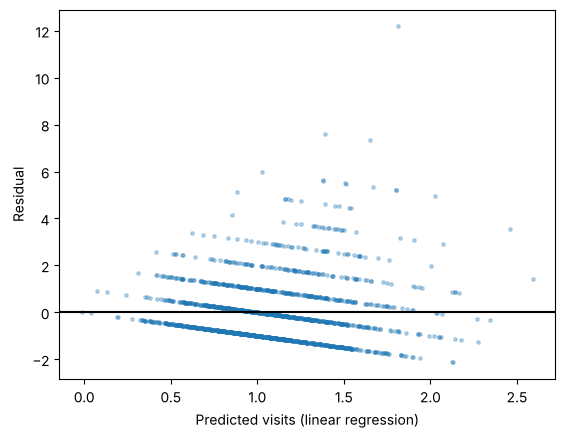

In [5]:
ols = smf.ols("ed_visits_6m" + RHS, data=df).fit()

plt.scatter(ols.fittedvalues, ols.resid, s=6, alpha=0.3)
plt.axhline(0, color="black")
plt.xlabel("Predicted visits (linear regression)")
plt.ylabel("Residual")
plt.show()

**Question 2.** What is wrong with linear regression here?

*Answer.* The residuals **fan out** as the predicted count grows, so the constant-variance assumption fails and the standard errors are wrong. Linear regression can also predict negative counts, and it adds a fixed number of visits per risk factor instead of multiplying the visit rate.

## 3. Poisson regression

The model is

log(expected visits in 6 months) = β₀ + β₁·age10 + β₂·egfr10 + β₃·diabetes + β₄·prior

The **log link** keeps every expected count positive, and it means that effects **multiply** the expected number of visits.

In [6]:
pois = smf.glm("ed_visits_6m" + RHS, data=df, family=fam.Poisson()).fit()
print(pois.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:           ed_visits_6m   No. Observations:                 1645
Model:                            GLM   Df Residuals:                     1640
Model Family:                 Poisson   Df Model:                            4
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -2369.3
Date:                Thu, 29 Oct 2026   Deviance:                       2470.8
Time:                        13:20:43   Pearson chi2:                 2.46e+03
No. Iterations:                     5   Pseudo R-squ. (CS):             0.1086
Covariance Type:            nonrobust                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           -0.1993      0.038  

In [7]:
print("1. Distribution:", type(pois.family).__name__)
print("2. Linear predictor:", " + ".join(pois.params.index))
print("3. Link:", type(pois.family.link).__name__)

1. Distribution: Poisson
2. Linear predictor: Intercept + age10 + egfr10 + diabetes + prior_admits_12m
3. Link: Log


## 4. Incidence rate ratios

Exponentiate the coefficients and their confidence limits: **exp(β) is an incidence rate ratio (IRR)**, the factor by which the expected number of visits is multiplied.

In [8]:
irr = np.exp(pd.concat([pois.params, pois.conf_int()], axis=1))
irr.columns = ["IRR", "2.5%", "97.5%"]
irr.round(2)

,IRR,2.5%,97.5%
Intercept,0.82,0.76,0.88
age10,1.09,1.04,1.15
egfr10,0.92,0.89,0.94
diabetes,1.33,1.21,1.47
prior_admits_12m,1.18,1.12,1.23


Worked interpretations:

- **Diabetes:** IRR 1.33. Patients with diabetes have 33% more ED visits in 6 months than similar patients without diabetes.
- **Intercept:** 0.82 is the reference patient's expected number of visits in 6 months.

**Question 3.** Interpret the IRRs for eGFR and prior admissions.

*Answer.* Each 10 points of higher eGFR is associated with 8% fewer visits (IRR 0.92). Each admission in the previous year is associated with 18% more visits (IRR 1.18); effects multiply, so two prior admissions give 1.18 × 1.18 ≈ 1.39.

## 5. Checking for overdispersion

Poisson assumes **variance = mean**. Check: the Pearson χ² statistic divided by its degrees of freedom should be close to 1.

In [9]:
print(f"Dispersion (Pearson chi2 / df): {pois.pearson_chi2 / pois.df_resid:.2f}")

zeros_expected = stats.poisson.pmf(0, pois.fittedvalues).sum()
print(f"Patients with no visits: observed {(y == 0).sum()}, Poisson expects {zeros_expected:.0f}")

Dispersion (Pearson chi2 / df): 1.50
Patients with no visits: observed 708, Poisson expects 594


**Question 4.** Is there overdispersion, and why does it matter?

*Answer.* Yes: the dispersion is 1.50 (above 1), and Poisson expects about 594 patients with no visits against 708 observed. Some patients visit far more often than the predictors explain. The rate ratios are usually still fine, but the Poisson **standard errors are too small**, so its confidence intervals are too narrow.

## 6. Negative binomial regression

The negative binomial adds one parameter, α, so that **variance = μ + α·μ²**. We estimate α first, then refit as a GLM.

In [10]:
alpha = smf.negativebinomial("ed_visits_6m" + RHS, data=df).fit(disp=0).params["alpha"]
print(f"alpha = {alpha:.2f}")

nb = smf.glm("ed_visits_6m" + RHS, data=df, family=fam.NegativeBinomial(alpha=alpha)).fit()

pd.DataFrame({
    "IRR Poisson": np.exp(pois.params),
    "IRR neg. binomial": np.exp(nb.params),
    "SE Poisson": pois.bse,
    "SE neg. binomial": nb.bse,
}).round(3)

alpha = 0.47


,IRR Poisson,IRR neg. binomial,SE Poisson,SE neg. binomial
Intercept,0.819,0.816,0.038,0.046
age10,1.092,1.094,0.025,0.031
egfr10,0.919,0.921,0.013,0.017
diabetes,1.333,1.327,0.048,0.060
prior_admits_12m,1.175,1.183,0.023,0.030


In [11]:
print(f"Dispersion: Poisson {pois.pearson_chi2 / pois.df_resid:.2f}, negative binomial {nb.pearson_chi2 / nb.df_resid:.2f}")

Dispersion: Poisson 1.50, negative binomial 0.99


**Question 5.** What changed when we moved from Poisson to negative binomial?

*Answer.* The rate ratios are almost identical, but the standard errors are 20–30% larger, so the confidence intervals are wider and more honest. The dispersion falls from 1.50 to about 1, so the negative binomial describes the variation in visits well.

## 7. Expected visits for two patients

- **Patient A:** 68 years, eGFR 75, no diabetes, no prior admissions.
- **Patient B:** 84 years, eGFR 35, diabetes, 2 prior admissions.

In [12]:
patients = pd.DataFrame({"age": [68, 84], "egfr": [75, 35], "diabetes": [0, 1], "prior_admits_12m": [0, 2]},
                        index=["A", "B"])
patients["age10"] = (patients["age"] - 75) / 10
patients["egfr10"] = (patients["egfr"] - 60) / 10

nb.get_prediction(patients).summary_frame().round(2)

,mean,mean_se,mean_ci_lower,mean_ci_upper
A,0.68,0.04,0.61,0.75
B,2.02,0.13,1.78,2.29


Patient A is expected to make about 0.7 ED visits in 6 months, Patient B about 2.0, three times as many.

### The effects built into the data

| Term | True effect | Negative binomial estimate (95% CI) |
|---|---|---|
| Reference patient | 0.80 visits per 6 months | 0.82 (0.75 to 0.89) |
| Age, per 10 years | IRR 1.05 | 1.09 (1.03 to 1.16) |
| eGFR, per +10 | IRR 0.92 | 0.92 (0.89 to 0.95) |
| Diabetes | IRR 1.28 | 1.33 (1.18 to 1.49) |
| Each prior admission | IRR 1.25 | 1.18 (1.11 to 1.26) |
| Overdispersion α | 0.50 | 0.47 |